# Uso de ML para problemas de clasificación

En este notebook revisaremos un ejemplo de proceso de entrenamiento de un modelo de aprendizaje automático para resolver un problema de clasificación.

## 0. Entendimiento previo

* ¿De dónde obtengo el dataset?
* ¿Qué predicciones queremos hacer con este dataset?

El dataset lo obtengo de kaggle. Es para clasificar estrellas. https://www.kaggle.com/code/ybifoundation/stars-classification

Quiero utilizar la informacion de las columnas para ver si puedo predecir el tipo de estrella, por ejemplo: Red Dwarf, Brown Dwarf o White Dwarf.

## 1. Cargar datos

Puntos relevantes:
* ¿Dónde están los datos?
* ¿En qué formato?
* ¿Cómo los puede leer?


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:
#Leemos el dataset (dataframe)
df = pd.read_csv("https://github.com/YBIFoundation/Dataset/raw/main/Stars.csv", header=0)

In [ ]:
df.head()

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro),Absolute magnitude (Mv),Star type,Star category,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Brown Dwarf,Red,M
1,3042,0.000500,0.1542,16.60,0,Brown Dwarf,Red,M
2,2600,0.000300,0.1020,18.70,0,Brown Dwarf,Red,M
3,2800,0.000200,0.1600,16.65,0,Brown Dwarf,Red,M
4,1939,0.000138,0.1030,20.06,0,Brown Dwarf,Red,M


In [ ]:
df

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro),Absolute magnitude (Mv),Star type,Star category,Star color,Spectral Class
0,3068,0.002400,0.1700,16.12,0,Brown Dwarf,Red,M
1,3042,0.000500,0.1542,16.60,0,Brown Dwarf,Red,M
2,2600,0.000300,0.1020,18.70,0,Brown Dwarf,Red,M
3,2800,0.000200,0.1600,16.65,0,Brown Dwarf,Red,M
4,1939,0.000138,0.1030,20.06,0,Brown Dwarf,Red,M
...,...,...,...,...,...,...,...,...
235,38940,374830.000000,1356.0000,-9.93,5,Hypergiant,Blue,O
236,30839,834042.000000,1194.0000,-10.63,5,Hypergiant,Blue,O
237,8829,537493.000000,1423.0000,-10.73,5,Hypergiant,White,A
238,9235,404940.000000,1112.0000,-11.23,5,Hypergiant,White,A


## 2. Análisis exploratorio

Puntos relevantes:

* ¿Cuántos datos tenemos?
* ¿Qué y cuántos campos tenemos?
* ¿Qué tipo de información contiene cada campo?
* ¿Qué tan "limpios" están los datos?
* ¿Qué rango de valores tiene cada campo?

NOTA: Justifica o argumenta con visualizaciones básicas

In [ ]:
# Analisis exploratorio
df.describe()

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro),Absolute magnitude (Mv),Star type
count,240.000000,240.000000,240.000000,240.000000,240.000000
mean,10497.462500,107188.361635,237.157781,4.382396,2.500000
std,9552.425037,179432.244940,517.155763,10.532512,1.711394
min,1939.000000,0.000080,0.008400,-11.920000,0.000000
25%,3344.250000,0.000865,0.102750,-6.232500,1.000000
50%,5776.000000,0.070500,0.762500,8.313000,2.500000
75%,15055.500000,198050.000000,42.750000,13.697500,4.000000
max,40000.000000,849420.000000,1948.500000,20.060000,5.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Temperature (K)          240 non-null    int64  
 1   Luminosity (L/Lo)        240 non-null    float64
 2   Radius (R/Ro)            240 non-null    float64
 3   Absolute magnitude (Mv)  240 non-null    float64
 4   Star type                240 non-null    int64  
 5   Star category            240 non-null    object 
 6   Star color               240 non-null    object 
 7   Spectral Class           240 non-null    object 
dtypes: float64(3), int64(2), object(3)
memory usage: 15.1+ KB


In [ ]:
df.dtypes

Temperature (K)              int64
Luminosity (L/Lo)          float64
Radius (R/Ro)              float64
Absolute magnitude (Mv)    float64
Star type                    int64
Star category               object
Star color                  object
Spectral Class              object
dtype: object

In [ ]:
df.columns


Index(['Temperature (K)', 'Luminosity (L/Lo)', 'Radius (R/Ro)',
       'Absolute magnitude (Mv)', 'Star type', 'Star category', 'Star color',
       'Spectral Class'],
      dtype='object')

Text(0, 0.5, 'Numbers of Stars')

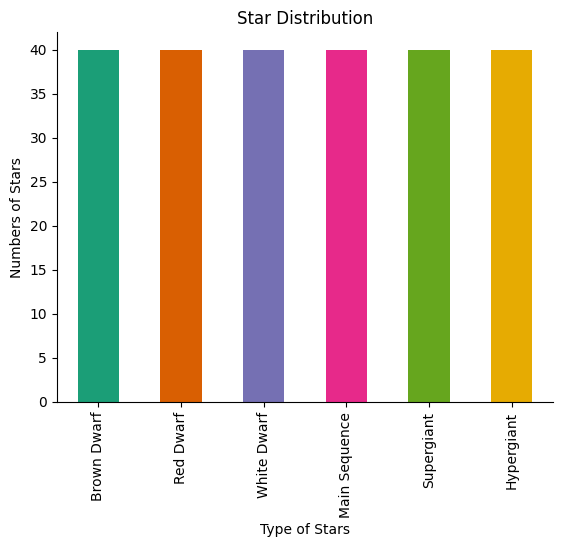

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
#df.groupby(5).size().plot(kind='bar', color=sns.palettes.mpl_palette('Dark2'))
df['Star category'].value_counts().plot(kind='bar', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)
plt.title("Star Distribution")
plt.xlabel("Type of Stars")
plt.ylabel("Numbers of Stars")

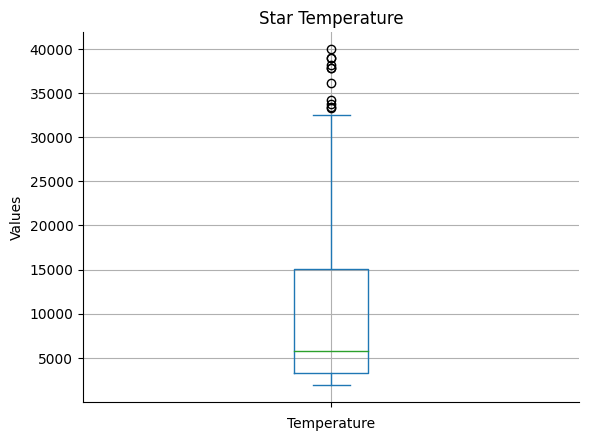

In [ ]:
# Plot a boxplot of the "Temperature (K)" column
data = df["Temperature (K)"]
data.name = None
data.plot(kind="box", grid=True, title="Star Temperature", xlabel="Temperature", ylabel="Values")

# Hide the top and right spines
plt.gca().spines[['top','right']].set_visible(False)

In [ ]:
df['Temperature (K)'].median()

5776.0

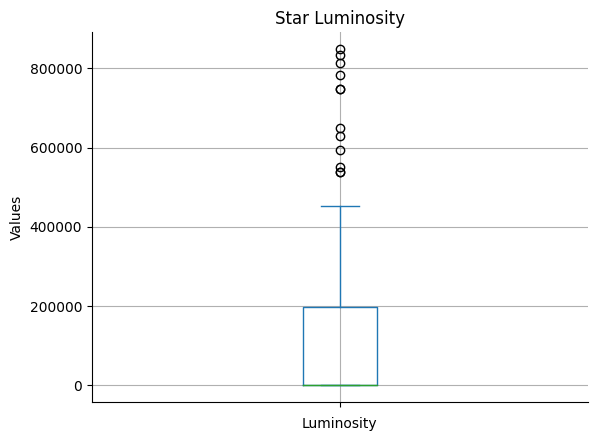

In [ ]:
# Plot a boxplot of the "Luminosity (L/Lo)" column
data2 = df["Luminosity (L/Lo)"]
data2.name = None
data2.plot(kind="box", grid=True, title="Star Luminosity", xlabel="Luminosity", ylabel="Values")

# Hide the top and right spines
plt.gca().spines[['top','right']].set_visible(False)

In [ ]:
df['Luminosity (L/Lo)'].median()

0.07050000000000001

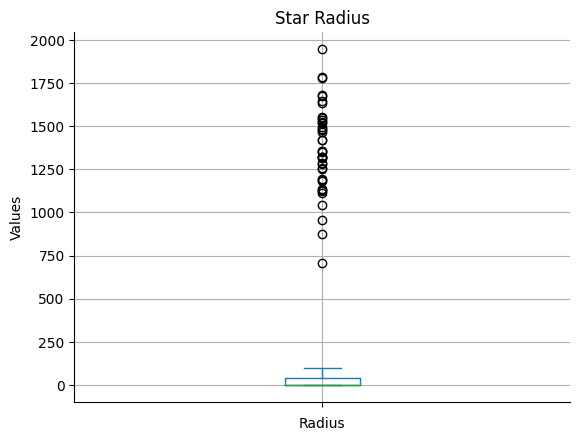

In [ ]:
# Plot a boxplot of the "Radius (R/Ro)" column
data3 = df["Radius (R/Ro)"]
data3.name = None
data3.plot(kind="box", grid=True, title="Star Radius", xlabel="Radius", ylabel="Values")

# Hide the top and right spines
plt.gca().spines[['top','right']].set_visible(False)

In [ ]:
df['Radius (R/Ro)'].median()

0.7625

## 3. Preprocesamiento

Puntos relevantes:

* ¿Qué información es relevante conservar?
* ¿Qué campo(s) son las variables de entrada?
* ¿Cuál campo es la variable de salida o etiqueta?

La informacion relevante para conservar es la temperatura, luminosidad, radio y categoria de estrella. Las variables de entrada son la temperatura, luminosidad y radio. La variable de salida o etiqueta es la categoria de la estrella.

In [ ]:
df['Temperature (K)']

0       3068
1       3042
2       2600
3       2800
4       1939
       ...  
235    38940
236    30839
237     8829
238     9235
239    37882
Length: 240, dtype: int64

In [ ]:
df['Luminosity (L/Lo)']

0           0.002400
1           0.000500
2           0.000300
3           0.000200
4           0.000138
           ...      
235    374830.000000
236    834042.000000
237    537493.000000
238    404940.000000
239    294903.000000
Length: 240, dtype: float64

In [ ]:
df['Radius (R/Ro)']

0         0.1700
1         0.1542
2         0.1020
3         0.1600
4         0.1030
         ...    
235    1356.0000
236    1194.0000
237    1423.0000
238    1112.0000
239    1783.0000
Length: 240, dtype: float64

In [ ]:
df['Star category']

0      Brown Dwarf
1      Brown Dwarf
2      Brown Dwarf
3      Brown Dwarf
4      Brown Dwarf
          ...     
235     Hypergiant
236     Hypergiant
237     Hypergiant
238     Hypergiant
239     Hypergiant
Name: Star category, Length: 240, dtype: object

### 3.1 Selección de características

* Vamos a quitar columnas que no parecen útiles.
* Vamos a seleccionar las columnas que podemos usar para hacer predicciones.

In [ ]:
df_pre = df.drop(columns = ['Absolute magnitude (Mv)', 'Star type', 'Star color', 'Spectral Class'])
df_pre


,Temperature (K),Luminosity (L/Lo),Radius (R/Ro),Star category
0,3068,0.002400,0.1700,Brown Dwarf
1,3042,0.000500,0.1542,Brown Dwarf
2,2600,0.000300,0.1020,Brown Dwarf
3,2800,0.000200,0.1600,Brown Dwarf
4,1939,0.000138,0.1030,Brown Dwarf
...,...,...,...,...
235,38940,374830.000000,1356.0000,Hypergiant
236,30839,834042.000000,1194.0000,Hypergiant
237,8829,537493.000000,1423.0000,Hypergiant
238,9235,404940.000000,1112.0000,Hypergiant


### 3.2 Acomodo de columnas

* Vamos a separar la parte del dataframe que utilizaremos como variables de entrada (X) y las etiquetas (y)

In [ ]:
df_x = df_pre.drop(columns=['Star category'])
df_y = df_pre['Star category']

In [ ]:
df_x

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro)
0,3068,0.002400,0.1700
1,3042,0.000500,0.1542
2,2600,0.000300,0.1020
3,2800,0.000200,0.1600
4,1939,0.000138,0.1030
...,...,...,...
235,38940,374830.000000,1356.0000
236,30839,834042.000000,1194.0000
237,8829,537493.000000,1423.0000
238,9235,404940.000000,1112.0000


In [ ]:
df_y

0      Brown Dwarf
1      Brown Dwarf
2      Brown Dwarf
3      Brown Dwarf
4      Brown Dwarf
          ...     
235     Hypergiant
236     Hypergiant
237     Hypergiant
238     Hypergiant
239     Hypergiant
Name: Star category, Length: 240, dtype: object

## 4. Entrenamiento de modelos

Puntos relevantes:
* ¿Cómo vamos a separar el dataset?
* ¿Es necesario normalizar? ¿Qué tipo de normalización?
* ¿Qué modelos vamos a probar?

### 4.1 Generación de dataset de entrenamiento y prueba (train/test)

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
df_x_train, df_x_test, df_y_train, df_y_test = train_test_split(df_x, df_y, test_size=0.15, random_state=19)

In [ ]:
df_x_train

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro)
189,3523,0.000957,0.1290
34,5800,0.810000,0.9000
121,3531,0.000930,0.0976
64,2935,0.000140,0.1160
186,2968,0.000461,0.1190
...,...,...,...
19,3441,0.039000,0.3510
168,17383,342900.000000,30.0000
98,12098,689.000000,7.0100
110,3459,100000.000000,1289.0000


In [ ]:
df_x_test

,Temperature (K),Luminosity (L/Lo),Radius (R/Ro)
138,3324,0.003400,0.34000
192,2994,0.007200,0.28000
181,2914,0.000631,0.11600
20,25000,0.056000,0.00840
129,2731,0.000437,0.08560
195,3598,0.002700,0.67000
237,8829,537493.000000,1423.00000
209,19360,0.001250,0.00998
228,23095,347820.000000,86.00000
60,3341,0.005600,0.05700


### 4.2 Normalizar (Escalar) datos de entrenamiento

**IMPORTANTE**: Ajustar la normalización en los datos de entrenamiento, NO en los datos de prueba.

#### 4.2.1 Normalización

<Axes: >

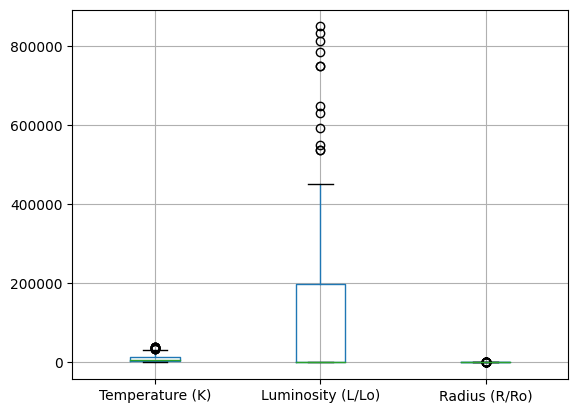

In [ ]:
# Normalizar es modificacion a los datos para conservar la distribucion, pero tenerlos en un alcance diferente
# boxplot de todas las columnas
df_x.boxplot()

In [ ]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [ ]:
minmax_scaler = MinMaxScaler().fit(df_x_train)

In [ ]:
minmax_scaler.data_min_

array([1.939e+03, 8.000e-05, 8.700e-03])

In [ ]:
minmax_scaler.data_range_

array([ 38061.     , 849419.99992,   1948.4913 ])

In [ ]:
df_x_norm_train = minmax_scaler.transform(df_x_train)
df_x_norm_test = minmax_scaler.transform(df_x_test)

{'whiskers': [<matplotlib.lines.Line2D at 0x7966a902c0d0>,
 'caps': [<matplotlib.lines.Line2D at 0x7966a902c550>,
 'boxes': [<matplotlib.lines.Line2D at 0x7966a8fffdf0>,
 'medians': [<matplotlib.lines.Line2D at 0x7966a902ca90>,
 'fliers': [<matplotlib.lines.Line2D at 0x7966a902cd30>,
 'means': []}

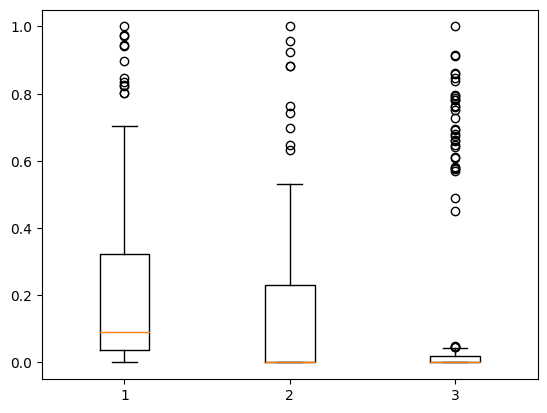

In [ ]:
plt.boxplot(df_x_norm_train)

### 4.3 Entrenar modelos base

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [ ]:
# Instanciar modelo
#model = LogisticRegression()
#model = DecisionTreeClassifier(max_depth=4)
model = SVC(kernel='rbf',C=1) # linea, poly, sigmoid, rbf
#model = MLPClassifier(activation='relu', hidden_layer_sizes=[10,10]) # relu, sigmoid, tanh, linear

In [ ]:
# Entrenar modelo con datos de entrenamiento
model.fit(df_x_norm_train, df_y_train)

SVC(C=1)

## 5. Evaluación del modelo

Puntos importantes:
* ¿Qué métricas nos conviene utilizar?
* ¿Qué desempeño necesitamos alcanzar?
* ¿Cuál métrica es prioridad?

### 5.1 Evaluación con datos de entrenamiento

In [ ]:
from sklearn.metrics import confusion_matrix

In [ ]:
df_y_train_pred = model.predict(df_x_norm_train)

In [ ]:
cm = confusion_matrix(df_y_train, df_y_train_pred)

In [ ]:
cm

array([[34,  0,  0,  0,  0,  0],
       [ 0, 32,  0,  0,  0,  0],
       [ 7,  0, 11,  0,  0, 17],
       [33,  0,  0,  0,  0,  0],
       [ 0,  0,  2,  0, 31,  0],
       [ 0,  0,  6,  0,  0, 31]])

In [ ]:
from sklearn.utils.multiclass import unique_labels

In [ ]:
def plot(y_true, y_pred):
  labels = unique_labels(df_y_train)
  column = [f'Predicted {label}' for label in labels]
  indeces = [f'Actual {label}' for label in labels]
  table = pd.DataFrame(confusion_matrix(df_y_train, df_y_train_pred),
                       columns=column, index=indeces)

  return table

In [ ]:
plot(df_y_train, df_y_train_pred)

,Predicted Brown Dwarf,Predicted Hypergiant,Predicted Main Sequence,Predicted Red Dwarf,Predicted Supergiant,Predicted White Dwarf
Actual Brown Dwarf,34,0,0,0,0,0
Actual Hypergiant,0,32,0,0,0,0
Actual Main Sequence,7,0,11,0,0,17
Actual Red Dwarf,33,0,0,0,0,0
Actual Supergiant,0,0,2,0,31,0
Actual White Dwarf,0,0,6,0,0,31


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

In [ ]:
pr = precision_score(df_y_train, df_y_train_pred, average='micro')
re = recall_score(df_y_train, df_y_train_pred, average='micro')
acc = accuracy_score(df_y_train, df_y_train_pred)
f1 = f1_score(df_y_train, df_y_train_pred, average='micro')
print("Train Precision: ", pr)
print("Train Recall: ", re)
print("Train F1: ", f1)
print("Train Accuracy: ", acc)

Train Precision:  0.6813725490196079
Train Recall:  0.6813725490196079
Train F1:  0.6813725490196079
Train Accuracy:  0.6813725490196079


### 5.2 Evaluación con datos de prueba

In [ ]:
df_y_test_pred = model.predict(df_x_norm_test)

In [ ]:
cm = confusion_matrix(df_y_test, df_y_test_pred)

In [ ]:
def plot(y_true, y_pred):
  labels = unique_labels(df_y_train)
  column = [f'Predicted {label}' for label in labels]
  indeces = [f'Actual {label}' for label in labels]
  table = pd.DataFrame(confusion_matrix(df_y_train, df_y_train_pred),
                       columns=column, index=indeces)

  return table

In [ ]:
plot(df_y_train, df_y_train_pred)

,Predicted Brown Dwarf,Predicted Hypergiant,Predicted Main Sequence,Predicted Red Dwarf,Predicted Supergiant,Predicted White Dwarf
Actual Brown Dwarf,34,0,0,0,0,0
Actual Hypergiant,0,32,0,0,0,0
Actual Main Sequence,7,0,11,0,0,17
Actual Red Dwarf,33,0,0,0,0,0
Actual Supergiant,0,0,2,0,31,0
Actual White Dwarf,0,0,6,0,0,31


In [ ]:
pr = precision_score(df_y_train, df_y_train_pred, average='micro')
re = recall_score(df_y_train, df_y_train_pred, average='micro')
acc = accuracy_score(df_y_train, df_y_train_pred)
f1 = f1_score(df_y_train, df_y_train_pred, average='micro')
print("Train Precision: ", pr)
print("Train Recall: ", re)
print("Train F1: ", f1)
print("Train Accuracy: ", acc)

Train Precision:  0.6813725490196079
Train Recall:  0.6813725490196079
Train F1:  0.6813725490196079
Train Accuracy:  0.6813725490196079


### 5.3 Validación cruzada

In [ ]:
# Manera adicional de asegurarnos que nuestros datos esten bien entrenados. Bien separados entre entrenamiento y prueba
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer

In [ ]:
precision_scorer = make_scorer(precision_score, pos_label='Brown Dwarf', average='micro')

In [ ]:
df_x_norm = minmax_scaler.transform(df_x)

In [ ]:
results = cross_val_score(model, df_x_norm, df_y, scoring=precision_scorer, cv=5)

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1561: UserWarning: Note that pos_label (set to 'Brown Dwarf') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1561: UserWarning: Note that pos_label (set to 'Brown Dwarf') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1561: UserWarning: Note that pos_label (set to 'Brown Dwarf') is ignored when average != 'binary' (got 'micro'). You may use labels=[pos_label] to specify a single positive class.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1561: UserWarning: Note that pos_label (set to 'Brown Dwarf') is ignored when average != 'binary' (got 'micro

En esta parte el codigo muestra una alerta (Warning), por usar el atributo pos_label='Brown Dwarf' en la funcion de make_scorer() de sklearn.metrics cuando utilizo el atributo average='micro' para clasificar con clases multiples. Si retiro este atributo, el array llamado resultados obtiene como respuesta de la funcion cross_val_scor() el valor de "nan". Esto es un error en la implementacion de la funcion make_scorer() de sklearn.metrics.

In [ ]:
results

array([0.72916667, 0.625     , 0.75      , 0.66666667, 0.70833333])

### 6. Guardar modelos

In [ ]:
from joblib import dump, load

In [ ]:
dump(model, 'modelo1.joblib')

['modelo1.joblib']

In [ ]:
# Cargar modelo
model2 = load('modelo1.joblib')